<a href="https://colab.research.google.com/github/husain-haekal/M.Husain-Haekal-B1C024041/blob/main/TM_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Library untuk pengolahan data numerik
import numpy as np
import pandas as pd

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengambil dataset Breast Cancer dari Scikit-learn
from sklearn.datasets import load_breast_cancer

# Library untuk membagi dataset dan normalisasi data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Library untuk membangun pipeline dan model klasifikasi
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Library untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Semua librari berhasil dimasukkan")

Semua librari berhasil dimasukkan


In [2]:
# Memuat Breast Cancer Wisconsin Dataset
data = load_breast_cancer()

# Mengambil fitur dan mengubahnya menjadi DataFrame
X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Mengambil label atau target kelas
y = data.target

# Menampilkan dimensi dataset
print("Dataset Shape:", X.shape)

# Menampilkan lima sampel pertama
print("\nFirst 5 Samples:")
print(X.head())

# Menampilkan nama kelas target
print("\nTarget Classes:")
print(data.target_names)

Dataset Shape: (569, 30)

First 5 Samples:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

In [3]:
# Menampilkan informasi umum dataset
print("Dataset Information:")
print(X.info())

# Memeriksa jumlah missing values
print("\nMissing Values:")
print(X.isnull().sum().sum())

# Menampilkan statistik deskriptif
print("\nStatistical Description:")
print(X.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

In [4]:
# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Menampilkan jumlah data
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Samples: 455
Testing Samples: 114

Training Features: (455, 30)
Testing Features: (114, 30)


In [5]:
# Membuat pipeline yang menggabungkan standardisasi dan Logistic Regression
model = make_pipeline(
    StandardScaler(),

    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model Training Completed!")

Model Training Completed!


In [6]:
# Melakukan prediksi menggunakan data testing
y_pred = model.predict(X_test)

# Menampilkan hasil prediksi
print("Predicted Classes:")
print(y_pred)

# Menampilkan label sebenarnya
print("\nActual Classes:")
print(y_test)

Predicted Classes:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Actual Classes:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [7]:
# Menghitung akurasi model
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.9824561403508771
Model Accuracy (%): 98.24561403508771


In [8]:
# Menampilkan classification report
print("Classification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    )
)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [9]:
# Mengambil probabilitas prediksi untuk kelas 1 (Benign)
y_probability = model.predict_proba(X_test)[:, 1]

# Menghitung nilai ROC-AUC
auc = roc_auc_score(y_test, y_probability)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.9953703703703703


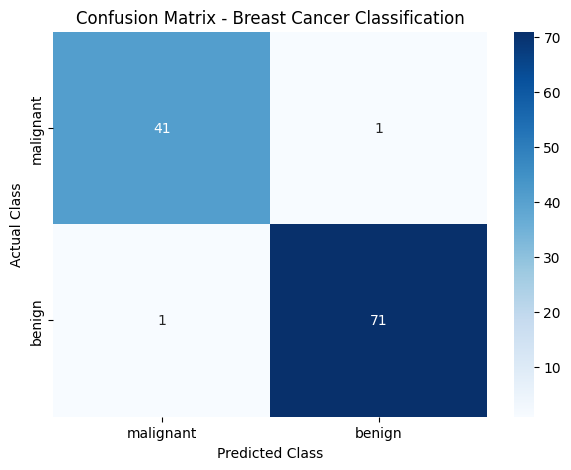

In [10]:
# Menghitung confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualisasi confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=data.target_names,
    yticklabels=data.target_names
)

plt.title("Confusion Matrix - Breast Cancer Classification")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [11]:
sample = X_test.iloc[[0]]

# Menampilkan fitur sampel
print("Input Sample:")
print(sample)

# Melakukan prediksi
prediction = model.predict(sample)[0]

# Mengambil probabilitas prediksi
probability = model.predict_proba(sample)[0]

# Mengubah label numerik menjadi nama kelas
result = data.target_names[prediction]

# Menampilkan hasil prediksi
print("\nPrediction Result:", result)

print("\nPrediction Probability:")

for class_name, prob in zip(data.target_names, probability):

    print(
        class_name,
        ":",
        round(prob * 100, 2),
        "%"
    )

Input Sample:
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
256        19.55         28.77           133.6     1207.0           0.0926   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
256            0.2063          0.1784               0.1144         0.1893   

     mean fractal dimension  ...  worst radius  worst texture  \
256                 0.06232  ...         25.05          36.27   

     worst perimeter  worst area  worst smoothness  worst compactness  \
256            178.6      1926.0            0.1281             0.5329   

     worst concavity  worst concave points  worst symmetry  \
256           0.4251                0.1941          0.2818   

     worst fractal dimension  
256                   0.1005  

[1 rows x 30 columns]

Prediction Result: malignant

Prediction Probability:
malignant : 100.0 %
benign : 0.0 %
